# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

*Answer:* 

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

In [2]:
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn


def classification_report(y_true, y_pred):
    # accuracy, precision, recall and F1 from the four counts
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn

    accuracy = (tp + tn)/n
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0

    return dict(TP = tp, FN = fn, FP = fp, TN = tn, accuracy = accuracy, precision = precision, recall = recall, specificity = specificity, f1 = f1, balanced_accuracy = balanced, mcc = mcc)


def roc_curve(y_true, scores):
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype = float)
    order = np.argsort(-scores, kind = "mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds


def auc_trapezoid(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))

def roc_auc(y_true, scores):
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype = float)
    _, inv, cnt = np.unique(scores, return_inverse = True, return_counts = True)
    first = np.cumsum(cnt) - cnt + 1
    ranks = (first + (cnt - 1) / 2)[inv]
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))



# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(5, 1, 1, 13) [[13  1]
 [ 1  5]]
0.8571428571428571 0.8571428571428572 0.8571428571428571


**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


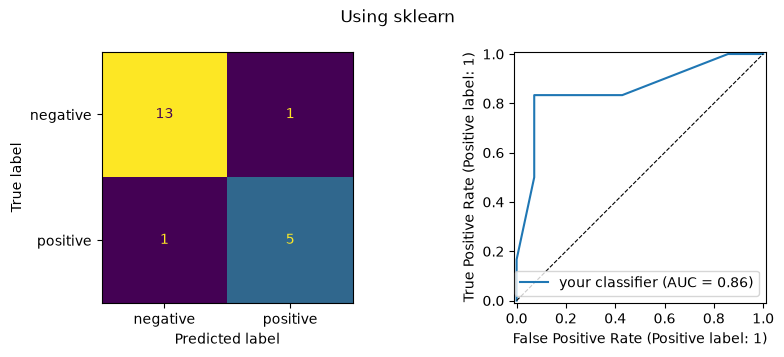


Using our own code
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
{'TP': 5, 'FN': 1, 'FP': 1, 'TN': 13, 'accuracy': 0.9, 'precision': 0.8333333333333334, 'recall': 0.8333333333333334, 'specificity': 0.9285714285714286, 'f1': 0.8333333333333334, 'balanced_accuracy': 0.8809523809523809, 'mcc': np.float64(0.7619047619047619)}
AUC 0.8571


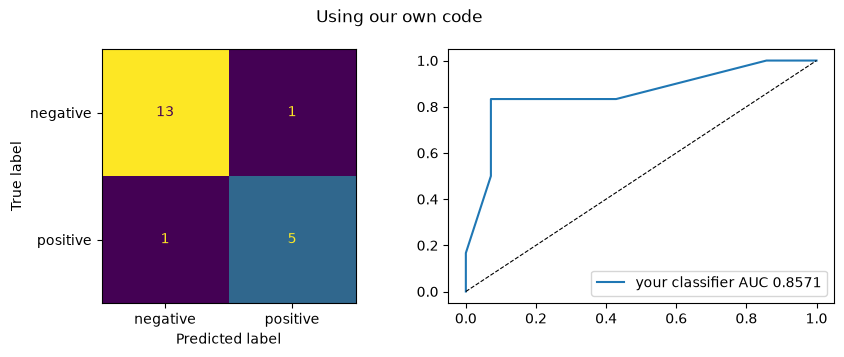

In [3]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.suptitle("Using sklearn")
plt.tight_layout(); plt.show()

# ---------------- Our own code

print("\nUsing our own code")
report = classification_report(y_test, y_pred)
tp, fn, fp, tn = confusion_matrix(y_small, s_small > 0.5)
ourown_cm = np.array([[tn, fp],[fn, tp]])


print(f"accuracy {report["accuracy"]:.4f}  precision {report["precision"]:.4f}  "
      f"recall {report["recall"]:.4f}  F1 {report["f1"]:.4f}")
print(classification_report(y_test, y_pred))

fpr, tpr, thresholds = roc_curve(y_test, p_test)
print(f"AUC {roc_auc(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(ourown_cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
ax[1].plot(fpr,tpr, label=f"your classifier AUC {roc_auc(y_test, p_test):.4f}")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.legend()
plt.suptitle("Using our own code")
plt.tight_layout(); #plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

### Installing tensorflow 
To access the mnist dataset, use tensorflow. Be sure to check which installation to use as it depends on operative system and if you have a dedicated GPU. I (Hannah) do not have a dedicated GPU, so i am using the CPU install as detailed here: https://www.tensorflow.org/install/pip#cpu
The same wepbage shows installation for MacOS and such 

In [14]:
#downloads the dataset the first time it is run. otherwise uses what is already stored on the disk
import tensorflow as tf

mnist_file  = tf.keras.datasets.mnist.load_data()


In [7]:
"""
This file contains function for task a)

Cost functions, their derivatives and activations function and their derivatives, 
that will be used in project 2. 
"""

import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import jax.numpy as jnp


"""Penalty terms for the different regression methods (OLS, Ridge and Lasso), and their gradients"""
class Penalty:
    """
    Penalty term and its gradient for the different regression methods
 
    Params:
        reg (str or None): None for OLS, "L2" for Ridge, "L1" for Lasso
        lmbda (float): penalty strength
    """
 
    def __init__(self, reg=None, lmbda=0.0):
        if reg not in (None, "L1", "L2"):
            raise ValueError("reg must be None, L1 or L2")
        self.reg = reg
        self.lmbda = lmbda

 
    def __call__(self, theta):
        """
        L1 (Lasso): lambda * sum|theta_j|,  L2 (Ridge): lambda * sum theta_j^2,  OLS: 0
 
        Params:
            theta (jnp.ndarray): model parameters
 
        Returns:
            float: scalar penalty value (0 for OLS)
        """

        if self.reg is None or self.lmbda == 0: #OLS
            return 0.0
        
        if self.reg == "L2":    #Ridge
            return self.lmbda * jnp.sum(theta ** 2)
        
        return self.lmbda * jnp.sum(jnp.abs(theta)) #Lasso

 
    def grad(self, theta):
        """
        L1: lambda * sgn(theta),  L2: 2 * lambda * theta,  OLS: 0
 
        Params:
            theta (jnp.ndarray): model parameters
 
        Returns:
            jnp.ndarray: same shape as theta
        """

        if self.reg is None or self.lmbda == 0: # OLS
            return jnp.zeros_like(theta)
        
        if self.reg == "L2":    #Ridge
            return 2.0 * self.lmbda * theta
        
        return self.lmbda * jnp.sign(theta) #Lasso
      


"""Mean square error function, derivative, cost function and gradient of cost function"""
class MSE:
    """Mean squared error"""
 
    def __call__(self, predict, target):
        """
        Mean square error: C = (1/n) * sum (predict_i - target_i)^2
 
        Params:
            predict (jnp.ndarray): model predictions
            target (jnp.ndarray): true values, same shape as predict
 
        Returns:
            float: MSE
        """
        return jnp.mean((predict - target) ** 2)

 
    def der(self, predict, target):
        """
        Derivative of MSE: dC/dpredict = (2/n) * (predict - target)
 
        Params:
            predict (jnp.ndarray): model predictions
            target (jnp.ndarray): true values, same shape as predict
 
        Returns:
            jnp.ndarray: same shape as predict
        """
        return 2.0 * (predict - target) / predict.size

 
    def linear_cost(self, X, y, theta, penalty=Penalty()):
        """
        MSE cost function for a linear model X @ theta (project 1 regression)
 
        Params:
            X (jnp.ndarray): design matrix, shape: (n, p)
            y (jnp.ndarray): target values, shape: (n, )
            theta (jnp.ndarray): parameters, shape: (p, )
            penalty (Penalty): Penalty() for OLS, Penalty("L2", lmbda) for Ridge, Penalty("L1", lmbda) for Lasso
 
        Returns:
            float: value of cost function
        """
        return self(X @ theta, y) + penalty(theta)

 
    def linear_grad(self, X, y, theta, penalty=Penalty()):
        """
        Gradient of the MSE cost: (2/n) X^T (X theta - y) + penalty gradient
 
        Params:
            X (jnp.ndarray): design matrix, shape: (n, p)
            y (jnp.ndarray): target values, shape: (n, )
            theta (jnp.ndarray): parameters, shape: (p, )
            penalty (Penalty): Penalty() for OLS, Penalty("L2", lmbda) for Ridge, Penalty("L1", lmbda) for Lasso
 
        Returns:
            jnp.ndarray: the gradient, same shape as theta
        """
        n = X.shape[0]
        return 2.0 / n * X.T @ (X @ theta - y) + penalty.grad(theta)
 

"""Multiclass cross entropy (softmax)"""

class CrossEntropy:
    """Multiclass cross entropy, used together with a softmax output layer"""
 
    epsilon = 1e-12     #to avoid log(0)
 
    def __call__(self, P, Y):
        """
        Multiclass cross entropy: C = - sum_i sum_k (y_ik log(p_ik)) (eq. 5.28)
 
        Params:
            P (jnp.ndarray): predicted class probabilities, shape: (n, K)
            Y (jnp.ndarray): one-hot encoded targets, shape: (n, K)
 
        Returns:
            float: cross entropy
        """
        P = jnp.clip(P, self.epsilon, 1.0)
        return -jnp.sum(Y * jnp.log(P))
 
    def der(self, P, Y):
        """
        Derivative of multiclass cross entropy: dC/dp_ik = - y_ik / p_ik
 
        Params:
            P (jnp.ndarray): predicted class probabilities, shape: (n, K)
            Y (jnp.ndarray): one-hot encoded targets, shape: (n, K)
 
        Returns:
            jnp.ndarray: same shape as P
        """
        P = jnp.clip(P, self.epsilon, 1.0)
        return -Y / P
 
    def softmax_delta(self, P, Y):
        """
        Combined derivative of softmax + cross entropy: dC/dz = P - Y (eq. 8.69)
        Used directly as the output error delta^L when the output layer is softmax
 
        Params:
            P (jnp.ndarray): predicted class probabilities (softmax output), shape: (n, K)
            Y (jnp.ndarray): one-hot encoded targets, shape: (n, K)
 
        Returns:
            jnp.ndarray: same shape as P
        """
        return P - Y


"""Activation functions"""

class Identity:
    """
    Linear activation f(z) = z
    """

    def __call__(self, z):
        """
        Params:
        z (jnp.ndarray): input to activation function
        
        Returns: 
            jnp.ndarray: z unchanged
        """

        return z

    def der(self, z):
        """
        f'(z) = 1
        """

        return jnp.ones_like(z)

class Sigmoid:
    """Sigmoid activation function"""
 
    def __call__(self, z):
        """
        Sigmoid: sigma(z) = 1 / (1 + exp(-z))
 
        Params:
            z (jnp.ndarray): Input to activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, every entry put to interval (0, 1)
        """
        return 1.0 / (1.0 + jnp.exp(-z))
 
    def der(self, z):
        """
        Derivative of sigmoid: sigma'(z) = sigma(z) * (1 - sigma(z))
 
        Params:
            z (jnp.ndarray): Input to activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, values in (0, 0.25]
        """
        s = self(z)
        return s * (1.0 - s)



class ReLU:
    """ReLU activation function """
 
    def __call__(self, z):
        """
        ReLU(z) = max(0, z) (eq. 8.23)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, negative entries are set to 0, positive entries are held
        """
        return jnp.where(z > 0, z, 0.0)
 
    def der(self, z):
        """
        ReLU'(z) = 1 for z > 0, 0 for z <= 0 (eq. 8.23)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, set to 1 for z > 0, and 0 for z <= 0, set to 0 at 0
        """
        return jnp.where(z > 0, 1.0, 0.0)
 

class LeakyReLU:
    """
    Leaky ReLU activation function
 
    Params:
        alpha (float): slope for negative inputs, default: 0.01
    """
 
    def __init__(self, alpha=0.01):
        self.alpha = alpha
 
    def __call__(self, z):
        """
        LReLU(z) = z for z > 0, alpha * z for z <= 0 (eq. 8.24)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, negative entries are scaled by alpha, positive entries are held
        """
        return jnp.where(z > 0, z, self.alpha * z)

 
    def der(self, z):
        """
        LReLU'(z) = 1 for z > 0, alpha for z <= 0 (eq. 8.24)
 
        Params:
            z (jnp.ndarray): Input to the activation function. z = a^(l - 1) W^l + b^l
 
        Returns:
            jnp.ndarray: same shape as z, set to 1 for z > 0, and alpha for z <= 0, set to alpha at 0
        """
        return jnp.where(z > 0, 1.0, self.alpha)

class Softmax:
    """
    Softmax activation for the output layer in multiclass classification
    """

    def __call__(self, z):
        """
        Softmax, row-wise: p_ik = exp(z_ik) / sum_l exp(z_il)
        
        Params:
            z (jnp.ndarray): input to the output layer, shape: (n, K)
            
        Returns: 
            jnp.ndarray: same shape as z, each row is a probability
        """

        e = jnp.exp(z - jnp.max(z, axis = 1, keepdims = True)) #numerical stability

        return e / jnp.sum(e, axis = 1, keepdims = True)


 


In [18]:
# your Project 2 network (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)
"""
This file contain the neural network function used for project 2.

Feed forward, backward propagation, predict
"""
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that hand and JAX agree to ~1e-15
import jax.numpy as jnp


class NeuralNetwork:
    def __init__(self, network_input_size, layer_output_sizes, activations, cost = MSE(), penalty = Penalty(), seed = 2026):
        self.activations = activations
        self.cost_obj = cost
        self.penalty = penalty
        self.layers = self.create_layers(network_input_size, layer_output_sizes, np.random.default_rng(seed))

    @staticmethod
    def create_layers(network_input_size, layer_output_sizes, rng):
        """
        Initilizes weights and bias for each layer

        Params:
            network_input_size (int): number of input features
            layer_output_sizes (list of int): number of nodes in each layer, the last one is the output layer
            rng (np.random.Generator): random number generator
    
        Returns:
            list of (W, b): W has shape (n_in, n_out), b has shape (n_out,)
        """

        layers = []
        i_size = network_input_size

        for layer_output_size in layer_output_sizes:
            W = jnp.asarray(rng.normal(0, 1 / np.sqrt(i_size), (i_size, layer_output_size)))
            b = jnp.zeros(layer_output_size) + 0.01
            layers.append((W, b))

            i_size = layer_output_size
        return layers


    def feed_forward(self, inputs):
        """
        Feed-forward pass, a^l = f(a^(l-1) W^l + b^l), used for predictions
    
        Params:
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            layers (list of (W, b)): weights and biases
            activation_funcs (list of callables): one activation function per layer
    
        Returns:
            jnp.ndarray: network output, shape: (n, n_outputs)
        """

        return self.jax_compliant_predict(self.layers, inputs)


    def cost(self, inputs, targets):
        """
        Total cost of network

        Params: 
            layers (list of (W, b)): weights and bias
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            activation_funcs (list of callables): one activation function per layer
            targets (jnp.ndarray): targets, same shape as outpu
            lmbda (float): penalty strength, default: 0.0
            reg (str or None): None,  "L1", "L2"
        """
        
        return self.jax_cost(self.layers, inputs, targets)


    def feed_forward_saver(self, inputs):
        """
        Feed-forward pass that also stores the inputs and z of every layer
    
        Params:
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            layers (list of (W, b)): weights and biases
            activation_funcs (list of callables): one activation function per layer
    
        Returns:
            layer_inputs (list): a^(l-1) for every layer
            zs (list): z^l for every layer
            a (jnp.ndarray): network output, shape: (n, n_outputs)
        """

        layer_inputs, zs = [], []
        a = inputs

        for (W, b), activation_func in zip(self.layers, self.activations):
            layer_inputs.append(a)
            z = a @ W + b
            a = activation_func(z)
            zs.append(z)
        return layer_inputs, zs, a


    def backpropagation(self, inputs, targets):
        """
        Backpropagation: gradients of the cost wrt. every W and b
    
        Params:
            inputs (jnp.ndarray): input data, shape: (n, n_features)
            layers (list of (W, b)): weights and biases
            activation_funcs (list of callables): one activation function per layer
            targets (jnp.ndarray): targets, shape (n, n_outputs), same shape as the output
            activation_ders (list of callables): derivatives of the activation functions
            cost_der (callable): dC/da^L, default: mse_der
            lmbda (float): penalty strength
            reg (str or None): None, "L1" or "L2" (penalty on the weights only), default: None

        Returns:
            list of (dC_dW, dC_db): same structure as layers
        """

        layer_inputs, zs, predict = self.feed_forward_saver(inputs)
        layer_grads = [() for _ in self.layers]

        #loops over the layers, from last to first
        for i in reversed(range(len(self.layers))):
            layer_input, z, activation = layer_inputs[i], zs[i], self.activations[i]
            if i == len(self.layers) - 1: 
                #last layer: cost derivative as dC/da(L)
                dC_da = self.cost_obj.der(predict, targets)
            else: 
                #all other layers: build on previous z derivative, dCda(i) = dCdz(i + 1) * dz(i + 1)da(i)
                W_next, b = self.layers[i + 1]
                dC_da = dC_dz @ W_next.T
                
            dC_dz = dC_da * activation.der(z)

            W, b = self.layers[i]
            dC_dW = layer_input.T @ dC_dz + self.penalty.grad(W)
            dC_db = jnp.sum(dC_dz, axis = 0)

            layer_grads[i] = (dC_dW, dC_db)

        return layer_grads

    def update_weights(self, layer_steps):
        """
        Applies the steps computed by the optimizer
        
        Params:
            layer_steps (list of (dW, db)): same stucture as layers 
        """

        self.layers = [(W - dW, b - db) for (W, b), (dW, db) in zip(self.layers, layer_steps)]


    #the next functions are to check the backproagation to JAX
    def jax_compliant_predict(self, layers, inputs):
        a = inputs
        for (W, b), activation_func in zip(layers, self.activations):
            a = activation_func(a @ W + b)
        return a


    def jax_cost(self, layers, inputs, targets):
        predict = self.jax_compliant_predict(layers, inputs)
        return self.cost_obj(predict, targets) + sum(self.penalty(W) for W, _ in layers)


    def jax_gradient(self, inputs, targets):
        """
        Gradient of the cost with jax.grad, same structure as compute_gradient
        """

        return jax.grad(self.jax_cost)(self.layers, inputs, targets)

    def gradient_check(self, inputs, targets):
        """
        finds the largest absolute difference between backpropagation and the jax_gradient
        """

        ours = self.backpropagation(inputs, targets)
        auto = self.jax_gradient(inputs, targets)
        return max(float(jnp.max(jnp.abs(g1 - g2))) for (dW1, db1), (dW2, db2) in zip (ours, auto) for g1, g2 in ((dW1, dW2), (db1, db2)))
        
""" From Project_2 general_functions """

class Scaler:
    """
    Normalizes a design matrix X and centers an array y, with the means and stds
    computed from the data it is fitted on 
 
    Based on p116 fit with intercept from lecturebook.
 
        Usage:
            scaler = Scaler().fit(X_train, y_train)
            X_train_s, y_train_s = scaler.transform(X_train, y_train)
            X_test_s, y_test_s = scaler.transform(X_test, y_test)
            y_pred = scaler.inverse_transform_y(model_output)   
    """
 
    def fit(self, X, y=None):
        """
        Computes the column means and stds of X, and the mean of y
 
            Params:
                X (NDArray): Design matrix
                y (NDArray or None): Target data
 
            Returns:
                self (Scaler): so that Scaler().fit(X, y) can be chained
        """

        self.X_mean = X.mean(axis=0)
        X_std = X.std(axis=0)
        self.X_std = jnp.where(X_std == 0, 1, X_std)   # leave constant columns alone
        self.y_mean = y.mean() if y is not None else 0.0
        return self
 
    def transform_X(self, X):
        """
        (X - X_mean) / X_std, with the fitted mean and std
        """
        return (X - self.X_mean) / self.X_std
 
    def transform_y(self, y):
        """
        y - y_mean, with the fitted mean
        """
        return y - self.y_mean
 
    def inverse_transform_y(self, y_scaled):
        """
        y_scaled + y_mean: brings predictions back to the original scale
        """
        return y_scaled + self.y_mean
 
    def transform(self, X, y):
        """
        Scales both X and y, 
        Returns: X_norm, y_centered
        """
        return self.transform_X(X), self.transform_y(y)
 
    def fit_transform(self, X, y):
        """
        Fits on X, y and scales them, 
        Returns: X_norm, y_centered
        """
        return self.fit(X, y).transform(X, y)

In [19]:


d = 4                               # your digit
(x_train, y_train), (x_test, y_test) = mnist_file         
x_train = x_train.reshape(x_train.size, -1) / 255.0
x_test = x_test.reshape(x_test.size, -1) / 255.0
y_train = (y_train == d).astype(float)
y_test = (y_test == d).astype(float)


scaler = Scaler().fit(x_train, y_train)

X_train_s, y_train_s = scaler.transform(x_train, y_train)
X_test_s, y_test_s = scaler.transform(x_test, y_test)


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.

In [20]:

class SGD:
    """
    (Stochastic) gradient descent
    """

    def __init__(self, gamma, momentum = 0.0):
        self.gamma, self.momentum = gamma, momentum
        self.reset()


    def reset(self):
        self.v = None


    def step(self, layer_grads):
        if self.v is None:
            self.v = zeros_like_grads(layer_grads)

        self.v = [(self.momentum * vW + self.gamma * dW, self.momentum * vb + self.gamma * db) for (dW, db), (vW, vb) in zip(layer_grads, self.v)]

        return self.v




**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?


**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [ ]:
...

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the sorted pass in
exercise 1, explaining the rank formula in exercise 1c, polishing this text)

What was done without them: …